In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import sympy as sp
from scipy.optimize import curve_fit
from scipy.optimize import fsolve
from scipy import integrate
from functions import interpdiv
from functions import Euler_Burgers
from functions import ShockTime_Burgers
from functions import Mapped_Euler_Burgers
from functions import ThreePointInterpolation
from functions import SpectralMethodInviscidBurgers
from functions import Mapped_SpectralMethodInviscidBurgers

# Spectral Method Using Fourier Transform Bases

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


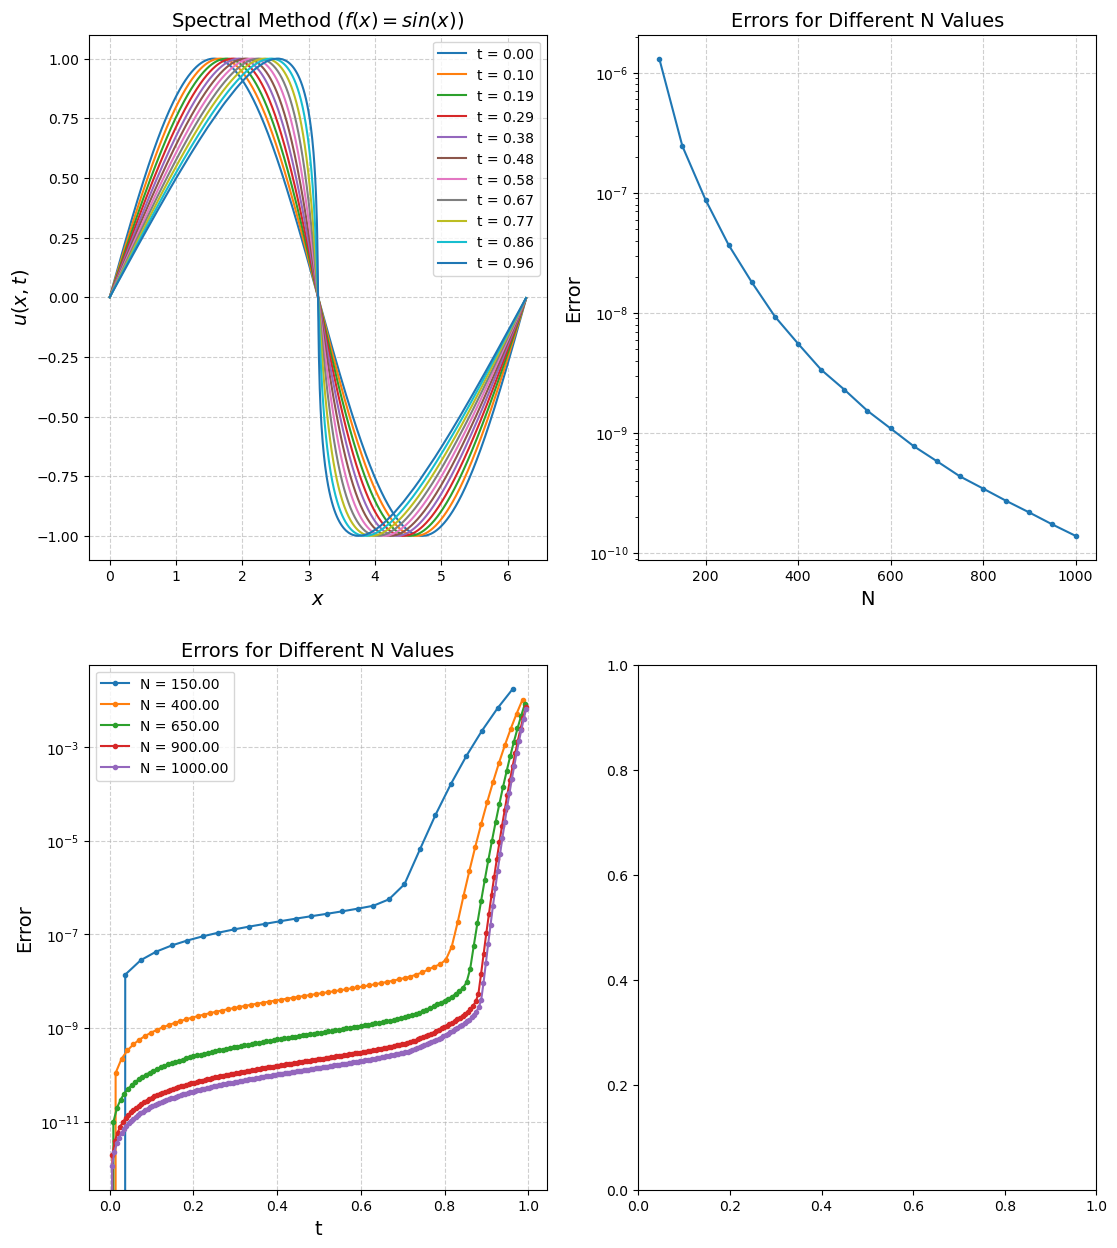

In [4]:
# Initial Condition 1:

# Set up x points
L = 2*np.pi
N = np.linspace(100, 1000, 19).astype(int)

uspec = []
mid_errors = []
time_step_errors = []
t_grid = []
for i in range(len(N)):
    # Grid Points
    x = np.linspace(0, L, N[i], endpoint = False)
    # IC for u is a sine wave
    u0 = np.sin(x)
    # Time discretization (CFL condition)
    t_start = 0.0
    t_end = ShockTime_Burgers(x, u0)
    CFL = 0.9
    delta_x = L / N[i]
    delta_t = CFL * delta_x / np.max(np.abs(u0))
    num_steps = int(np.round((t_end - t_start) / delta_t))
    t = np.linspace(t_start, t_end, num_steps, endpoint=False)
    t_grid.append(t)
    
    # Solve PDE
    uspec.append(SpectralMethodInviscidBurgers(u0, L, x, t))

    # Error
    u_exact = np.sin(x[None, :] - uspec[i] * t[:, None])
    error = np.abs(uspec[i] - u_exact)

    t_target = 0.5 * t_end
    idx = np.argmin(np.abs(t - t_target))

    mid_errors.append(np.max(error[idx]))
    time_step_errors.append(np.max(error, axis=1))
    
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(13, 15))

for i in range(0, len(t), len(t)//10):   # plot ~10 snapshots
    ax1.plot(x, uspec[-1][i], label=f"t = {t[i]:.2f}")
ax1.set_title("Spectral Method $(f(x) = sin(x))$", fontsize = 14)
ax1.set_xlabel(r"$x$", fontsize = 14)
ax1.set_ylabel(r"$u(x,t)$", fontsize = 14)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(N, mid_errors, marker='.')
ax2.set_title("Errors for Different N Values", fontsize = 14)
ax2.set_xlabel("N", fontsize = 14)
ax2.set_ylabel("Error", fontsize = 14)
ax2.set_yscale("log")
ax2.grid(True, linestyle="--", alpha=0.6)

ax3.plot(t_grid[1], time_step_errors[1], marker='.', label=f"N = {N[1]:.2f}")
ax3.plot(t_grid[6], time_step_errors[6], marker='.', label=f"N = {N[6]:.2f}")
ax3.plot(t_grid[11], time_step_errors[11], marker='.', label=f"N = {N[11]:.2f}")
ax3.plot(t_grid[16], time_step_errors[16], marker='.', label=f"N = {N[16]:.2f}")
ax3.plot(t_grid[18], time_step_errors[18], marker='.', label=f"N = {N[18]:.2f}")
ax3.set_yscale("log")
ax3.set_title("Errors for Different N Values", fontsize = 14)
ax3.set_xlabel("t", fontsize = 14)
ax3.set_ylabel("Error", fontsize = 14)
ax3.legend()
ax3.grid(True, linestyle="--", alpha=0.6)

plt.savefig("SpectralMethodInviscidBurgers_Post-Aliasing.jpg")
plt.show()

[2.709024116143155e-10, -9.57012247226885e-14, -3.3306690738754696e-16, 4.440892098500626e-16, -2.220446049250313e-16, 0.0, 1.1102230246251565e-16, -2.220446049250313e-16, 1.1102230246251565e-16, 2.220446049250313e-16, -1.1102230246251565e-16, 0.0, 3.3306690738754696e-16, 2.220446049250313e-16, 1.1102230246251565e-16, -1.1102230246251565e-16, 1.1102230246251565e-16, 0.0, -2.220446049250313e-16]


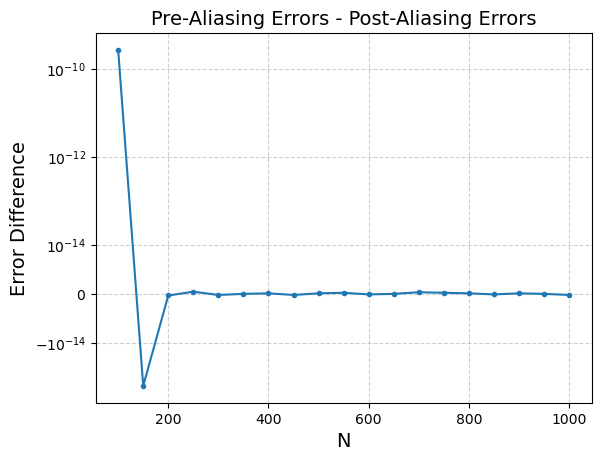

In [5]:
#pre_al = mid_errors
#post_al = mid_errors
#result = [x - y for x, y in zip(pre_al, post_al)]
# 0.8 * t
#result = [-0.00031007218655548785, -0.00015882174196996113, -1.146061814333299e-05, -1.083322761025185e-06, -9.76436158039995e-08, -4.964091893100431e-08, -1.4355148181266486e-09, -5.434985239638479e-10, -1.044381803261274e-10, -5.932532243235755e-11, 5.3052007231713105e-12, 6.985523270941485e-13, 6.261657858885883e-14, 1.1601830607332886e-14, -1.1102230246251565e-14, -1.7208456881689926e-15, 1.6653345369377348e-16, 1.6653345369377348e-16, -1.6653345369377348e-16]
# 0.5 * t
result = [2.709024116143155e-10, -9.57012247226885e-14, -3.3306690738754696e-16, 4.440892098500626e-16, -2.220446049250313e-16, 0.0, 1.1102230246251565e-16, -2.220446049250313e-16, 1.1102230246251565e-16, 2.220446049250313e-16, -1.1102230246251565e-16, 0.0, 3.3306690738754696e-16, 2.220446049250313e-16, 1.1102230246251565e-16, -1.1102230246251565e-16, 1.1102230246251565e-16, 0.0, -2.220446049250313e-16]

print(result)
plt.plot(N, result, marker = '.')
plt.title("Pre-Aliasing Errors - Post-Aliasing Errors", fontsize = 14)
plt.ylabel("Error Difference", fontsize = 14)
plt.xlabel("N", fontsize = 14)
plt.yscale('symlog', linthresh=1e-14)
plt.grid(True, linestyle="--", alpha=0.6)
#plt.savefig("SpectralMethodInviscidBurgers_Aliasing_Comparison.jpg")
plt.show()

Number of Time Steps 1416
max e1: 0.7059354138085672
max e2: 0.33674589668886745
Number of Time Steps 2833
max e1: 0.3108360176335738
max e2: 0.13862896412383718
Number of Time Steps 5666
max e1: 0.09367934693387436
max e2: 0.02240467484584996
Number of Time Steps 11333
max e1: 0.025471720121626795
max e2: 0.0020010144942463892


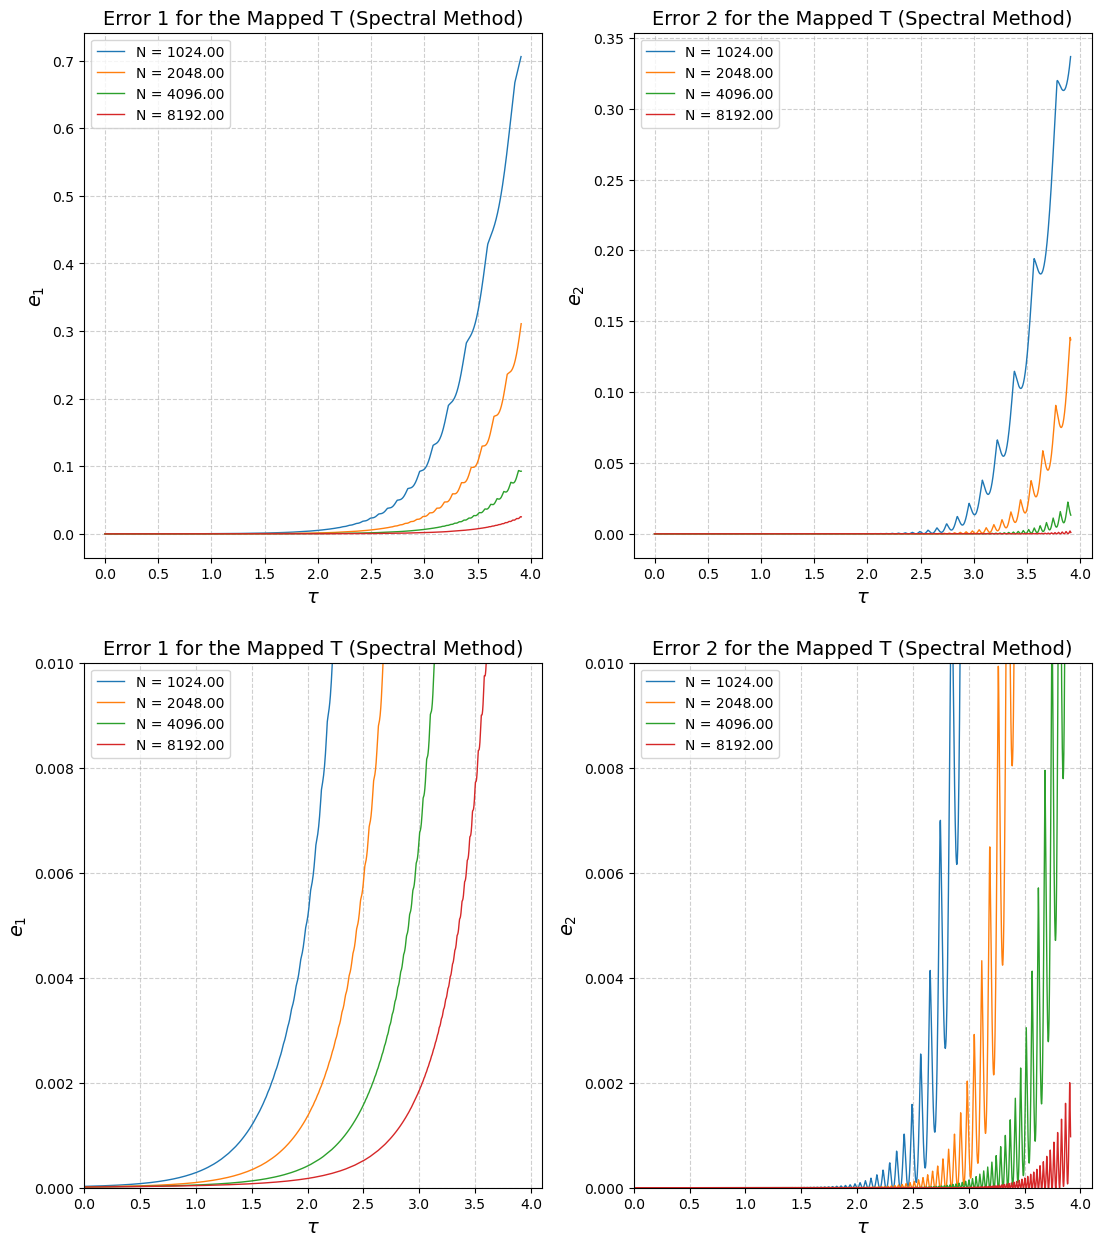

In [7]:
Resolution = [1024, 2048, 4096, 8192]
#Resolution = [1034, 2048, 4096, 16384]
L = 2*np.pi
x_map = np.linspace(0, L, 1000, endpoint = False)
u0_map = 1 + np.cos(x_map)
t_start = abs(np.log(ShockTime_Burgers(x_map, u0_map)))
t_end = - np.log(ShockTime_Burgers(x_map, u0_map) - 0.98)
T_star = ShockTime_Burgers(x_map, u0_map)
x_val = [[], [], [], []]
t_val = [[], [], [], []]
t_map_val = [[], [], [], []]
v = [[], [], [], []]
e1 = [[], [], [], []]
e2 = [[], [], [], []]
e1_exactish = [[], [], [], []]
e2_exactish = [[], [], [], []]
relative_error = [[], [], [], []]
CFL = 0.9

for i in range(len(Resolution)):
    x_val[i] = np.linspace(0, L, Resolution[i], endpoint = False)
    u0_map = 1 + np.cos(x_val[i])
    
    delta_x = L / Resolution[i]
    delta_t = CFL * delta_x / np.max(np.abs(u0_map))
    num_steps = int((t_end - t_start) / delta_t)
    
    print(f'Number of Time Steps {num_steps}')
    
    t_map_val[i] = np.linspace(t_start, t_end, num_steps, endpoint=False)
    t_val[i] = T_star - np.exp(-t_map_val[i])
    v[i] = Mapped_SpectralMethodInviscidBurgers(u0_map, L, x_val[i], t_map_val[i])

    u_for_e = SpectralMethodInviscidBurgers(u0_map, L, x_val[i], t_val[i])
    dx = x_val[i][1] - x_val[i][0]
    du_dx = np.gradient(u_for_e, dx, axis=1)

    # Error 1
    vhat = np.fft.fft(v[i], axis=1)
    E_map = L * 0.5 / (Resolution[i]**2) * np.sum(np.abs(vhat)**2, axis=1)
    E = integrate.simpson((abs(u0_map))**2, x = x_val[i])/2
    e2[i] = 2 * t_map_val[i] + np.log(E_map) - np.log(T_star**2 * 1.5*np.pi)
    ux = (np.roll(u_for_e, -1, axis=1) - np.roll(u_for_e, 1, axis=1)) / (2 * dx)

    ux_inf = ThreePointInterpolation(ux)
    e1[i] = 2 * (t_map_val[i] - np.log(ux_inf))
    E_map_exactish = T_star**2 * E * np.exp(-2 * t_map_val[i])
    e1_exactish[i] = 2.0 * (t_map_val[i] - np.log(np.sqrt(E / E_map_exactish)))
    e2_exactish[i] = 2 * t_map_val[i] + np.log(E_map_exactish) - np.log(E)

    print("max e1:", np.max(np.abs(e1[i])))
    print("max e2:", np.max(np.abs(e2[i])))

# Plot Results
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(13, 15))
for i in range(0, len(t_map_val)):
    ax1.plot(t_map_val[i], e1[i], lw=1, label=f"N = {Resolution[i]:.2f}")
#ax1.plot(t_map_val[-1], e1_exactish[-1], lw=1, label=f"Exact N = {Resolution[-1]:.2f}")
ax1.set_title("Error 1 for the Mapped T (Spectral Method)", fontsize=14)
ax1.set_xlabel(r"$\tau$", fontsize=14)
ax1.set_ylabel(r"$e_1$", fontsize=14)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

for i in range(0, len(t_map_val)):
    ax2.plot(t_map_val[i], e2[i], lw=1, label=f"N = {Resolution[i]:.2f}")
#ax2.plot(t_map_val[-1], e2_exactish[-1], lw=1, label=f"Exact N = {Resolution[-1]:.2f}")
ax2.set_title("Error 2 for the Mapped T (Spectral Method)", fontsize=14)
ax2.set_xlabel(r"$\tau$", fontsize=14)
ax2.set_ylabel(r"$e_2$", fontsize=14)
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)

for i in range(0, len(t_map_val)):
    ax3.plot(t_map_val[i], e1[i], lw=1, label=f"N = {Resolution[i]:.2f}")
#ax3.plot(t_map_val[-1], e1_exactish[-1], lw=1, label=f"Exact N = {Resolution[-1]:.2f}")
ax3.set_title("Error 1 for the Mapped T (Spectral Method)", fontsize=14)
ax3.set_xlabel(r"$\tau$", fontsize=14)
ax3.set_ylabel(r"$e_1$", fontsize=14)
ax3.set_xlim(0, 4.1)
ax3.set_ylim(0, 1e-2)
ax3.legend()
ax3.grid(True, linestyle="--", alpha=0.6)

for i in range(0, len(t_map_val)):
    ax4.plot(t_map_val[i], e2[i], lw=1, label=f"N = {Resolution[i]:.2f}")
#ax4.plot(t_map_val[-1], e2_exactish[-1], lw=1, label=f"Exact N = {Resolution[-1]:.2f}")
ax4.set_title("Error 2 for the Mapped T (Spectral Method)", fontsize=14)
ax4.set_xlabel(r"$\tau$", fontsize=14)
ax4.set_ylabel(r"$e_2$", fontsize=14)
ax4.set_xlim(0, 4.1)
ax4.set_ylim(0, 1e-2)
ax4.legend()
ax4.grid(True, linestyle="--", alpha=0.6)

Text(0, 0.5, '$e_2$')

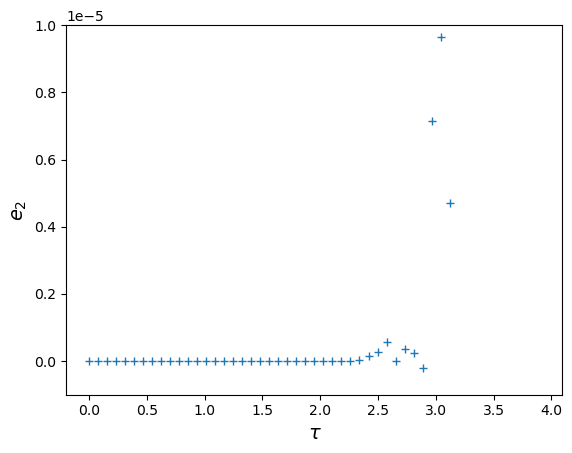

In [9]:
step1 = len(t_map_val[3])//50
sample1 = slice(None, None, step1)
step2 = len(t_map_val[2])//50
sample2 = slice(None, None, step2)
step3 = len(t_map_val[1])//50
sample3 = slice(None, None, step3)
step4 = len(t_map_val[0])//50
sample4 = slice(None, None, step4)
plt.plot(t_map_val[3][sample1], e2[3][sample1], marker = '+', linestyle='')
#plt.plot(t_map_val[3][sample1], e1[3][sample1], marker = 'o', linestyle='')
#plt.plot(t_map_val[2][sample2], e2[2][sample2], marker = 'o', linestyle='')
#plt.plot(t_map_val[1][sample3], e2[1][sample3], marker = '*', linestyle='')
#plt.plot(t_map_val[0][sample4], e2[0][sample4], marker = '.', linestyle='')
#plt.plot(t_map_val[3], t_map_val[3], marker = '.')
#plt.xlim(1.001, 1.003)
plt.ylim(-0.000001, 0.00001)
#plt.plot(np.linspace(1,len(t_map_val[3]),len(t_map_val[3])), t_map_val[3], marker = '.')
#plt.xlim(1000, 1010)
#plt.ylim(0.5, 0.6)
plt.xlabel(r"$\tau$", fontsize=14)
plt.ylabel(r"$e_2$", fontsize=14)

In [10]:
a = E_map
b = t_map_val[3]
print(a)
print(b)
2 * b + np.log(a) - np.log(1.5*np.pi)

[4.71238898e+00 4.70913706e+00 4.70588737e+00 ... 1.89213985e-03
 1.89074797e-03 1.88935824e-03]
[6.57974493e-06 3.51738793e-04 6.96897841e-04 ... 3.91065859e+00
 3.91100375e+00 3.91134891e+00]


array([1.31594899e-05, 1.31594896e-05, 1.31594902e-05, ...,
       1.07530132e-03, 1.02973712e-03, 9.84769202e-04])